# Isolation Forest: Vehicle-Level Anomaly Detection

**Project:** Mining EV Registration Patterns in Washington State

**Question:** Which vehicles have an unusual combination of model year and electric range within their EV type?

Only vehicles with a positive recorded range are used (zero range means "not researched", so it is treated as missing). BEVs and PHEVs get separate models. Settings follow the methods plan: 200 trees, `max_samples=256`, `contamination="auto"`, `random_state=42`, and a review of roughly the top 1% by anomaly score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest

data = pd.read_csv("data/processed/week09/anomaly_vehicles.csv")
features = ["Model Year", "Electric Range Usable"]

print("Anomaly table:", data.shape)
print("Vehicles by type:", data["EV_Type"].value_counts().to_dict())
print("Missing values in features:", int(data[features].isna().sum().sum()))
print("Unique vehicle IDs:", data["DOL Vehicle ID"].is_unique)
print("Smallest range:", data["Electric Range Usable"].min(), "(zero would mean a missing value slipped through)")
print()
print(data.groupby("EV_Type")[features].describe().round(1).T.to_string())

Anomaly table: (17202, 6)
Vehicles by type: {'PHEV': 9698, 'BEV': 7504}
Missing values in features: 0
Unique vehicle IDs: True
Smallest range: 1.0 (zero would mean a missing value slipped through)

EV_Type                         BEV    PHEV
Model Year            count  7504.0  9698.0
                      mean   2017.6  2021.4
                      std       2.3     3.7
                      min    1999.0  2010.0
                      25%    2016.0  2018.0
                      50%    2018.0  2023.0
                      75%    2019.0  2024.0
                      max    2024.0  2027.0
Electric Range Usable count  7504.0  9698.0
                      mean    199.4    32.0
                      std      71.9    13.4
                      min      57.0     1.0
                      25%     150.0    22.0
                      50%     215.0    32.0
                      75%     238.0    38.0
                      max     337.0   153.0


## 1. Fit one model per vehicle type

The score is `-score_samples`, so a **higher score means more unusual**. Features stay in their original units, because Isolation Forest uses random splits, not distances.

Many vehicles share exactly the same model year and range (for example, every 2012 Prius with 6 miles), so they receive exactly the same score. If the 1% cutoff falls inside such a group, ranking would flag only some identical vehicles, and which ones would be arbitrary. We therefore flag every vehicle scoring **at or above the 1% cutoff score**, which can make the flagged group slightly larger than 1%.

In [2]:
PARAMS = dict(n_estimators=200, max_samples=256, contamination="auto")
SEED = 42
TOP_SHARE = 0.01

parts, summary = [], []
for ev_type in ["BEV", "PHEV"]:
    d = data[data["EV_Type"] == ev_type].copy()
    model = IsolationForest(random_state=SEED, **PARAMS).fit(d[features])
    d["anomaly_score"] = -model.score_samples(d[features])
    d["auto_flag"] = model.predict(d[features]) == -1

    n_target = int(round(TOP_SHARE * len(d)))
    cutoff = d["anomaly_score"].nlargest(n_target).min()
    d["top_flag"] = d["anomaly_score"] >= cutoff
    d["score_rank"] = d["anomaly_score"].rank(ascending=False, method="min").astype(int)

    summary.append({
        "EV_Type": ev_type,
        "Vehicles": len(d),
        "Target_top_1pct": n_target,
        "Cutoff_score": round(cutoff, 4),
        "Flagged_at_or_above_cutoff": int(d["top_flag"].sum()),
        "Flagged_percent": round(d["top_flag"].mean() * 100, 2),
        "Flagged_by_auto_threshold": int(d["auto_flag"].sum()),
        "Distinct_year_range_pairs": len(d[features].drop_duplicates()),
    })
    parts.append(d)

scored = pd.concat(parts)
print(pd.DataFrame(summary).set_index("EV_Type").T.to_string())

EV_Type                           BEV      PHEV
Vehicles                    7504.0000  9698.000
Target_top_1pct               75.0000    97.000
Cutoff_score                   0.6652     0.683
Flagged_at_or_above_cutoff    77.0000   149.000
Flagged_percent                1.0300     1.540
Flagged_by_auto_threshold   2756.0000  3159.000
Distinct_year_range_pairs    113.0000   237.000


`contamination="auto"` uses the model's own default threshold and flags far more than 1% of vehicles, so it is not a useful short list. We use the top 1% by score as a review budget, as planned.

In [3]:
flagged = scored[scored["top_flag"]]

for ev_type in ["BEV", "PHEV"]:
    top = flagged[flagged["EV_Type"] == ev_type]
    table = (top.groupby(["Make", "Model", "Model Year", "Electric Range Usable"])
                .agg(Vehicles=("anomaly_score", "size"), Score=("anomaly_score", "mean"))
                .sort_values("Score", ascending=False).round(3).reset_index())
    print(ev_type, "- flagged vehicles:", len(top))
    print(table.to_string(index=False))
    print()

BEV - flagged vehicles: 77
   Make     Model  Model Year  Electric Range Usable  Vehicles  Score
   FORD    RANGER        2000                   58.0         2  0.726
 TOYOTA      RAV4        2002                   95.0         1  0.708
 TOYOTA      RAV4        2003                   95.0         1  0.706
  TESLA  ROADSTER        2008                  220.0         3  0.703
  TESLA  ROADSTER        2010                  245.0         5  0.690
  TESLA   MODEL S        2012                  265.0        18  0.689
PORSCHE     MACAN        2024                  308.0        11  0.687
   FORD    RANGER        1999                   74.0         1  0.685
  TESLA  ROADSTER        2011                  245.0         5  0.679
   MINI   HARDTOP        2021                  110.0        16  0.675
  SMART EQ FORTWO        2019                   58.0         4  0.671
  SMART EQ FORTWO        2018                   58.0        10  0.665

PHEV - flagged vehicles: 149
                Make  Model  Mode

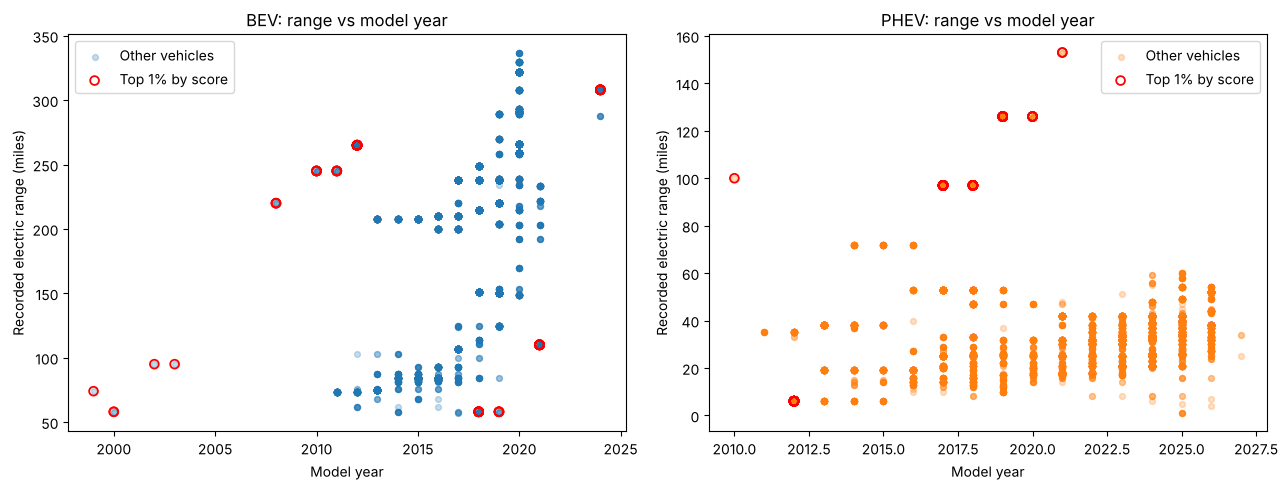

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for a, ev_type, color in zip(ax, ["BEV", "PHEV"], ["tab:blue", "tab:orange"]):
    d = scored[scored["EV_Type"] == ev_type]
    f = d[d["top_flag"]]
    a.scatter(d["Model Year"], d["Electric Range Usable"], s=18, alpha=0.25, color=color, label="Other vehicles")
    a.scatter(f["Model Year"], f["Electric Range Usable"], s=40, facecolors="none", edgecolors="red", linewidths=1.3, label="Top 1% by score")
    a.set_title(ev_type + ": range vs model year")
    a.set_xlabel("Model year")
    a.set_ylabel("Recorded electric range (miles)")
    a.legend()
plt.tight_layout()
plt.show()

## 2. Compare with the earlier IQR check

The IQR rule looks at range only, for each EV type. Isolation Forest looks at model year and range together, so the two can disagree.

In [5]:
rows = []
for ev_type in ["BEV", "PHEV"]:
    d = scored[scored["EV_Type"] == ev_type]
    q1, q3 = d["Electric Range Usable"].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr = (d["Electric Range Usable"] < low) | (d["Electric Range Usable"] > high)
    rows.append({
        "EV_Type": ev_type,
        "IQR_lower_fence": low, "IQR_upper_fence": high,
        "IQR_flags": int(iqr.sum()),
        "IsolationForest_flags": int(d["top_flag"].sum()),
        "Flagged_by_both": int((iqr & d["top_flag"]).sum()),
        "IsolationForest_only": int((~iqr & d["top_flag"]).sum()),
        "IQR_only": int((iqr & ~d["top_flag"]).sum()),
    })
print(pd.DataFrame(rows).set_index("EV_Type").T.to_string())

phev = scored[scored["EV_Type"] == "PHEV"]
print()
print("PHEV IQR flags by model:")
q1, q3 = phev["Electric Range Usable"].quantile([0.25, 0.75])
print(phev[phev["Electric Range Usable"] > q3 + 1.5 * (q3 - q1)].groupby(["Make", "Model"]).size().to_string())

glc = phev[(phev["Make"] == "MERCEDES-BENZ") & (phev["Model"] == "GLC-CLASS") & (phev["Electric Range Usable"] <= 1)]
print()
print("Mercedes GLC-Class vehicles with a 1-mile range:", len(glc),
      "| score rank:", int(glc["score_rank"].min()), "of", len(phev),
      "| flagged:", bool(glc["top_flag"].any()))

EV_Type                  BEV   PHEV
IQR_lower_fence         18.0   -2.0
IQR_upper_fence        370.0   62.0
IQR_flags                0.0  174.0
IsolationForest_flags   77.0  149.0
Flagged_by_both          0.0   85.0
IsolationForest_only    77.0   64.0
IQR_only                 0.0   89.0

PHEV IQR flags by model:
Make                  Model 
BMW                   I3        173
WHEEGO ELECTRIC CARS  WHEEGO      1

Mercedes GLC-Class vehicles with a 1-mile range: 4 | score rank: 241 of 9698 | flagged: False


## 3. How stable are the flags?

We refit each model with 20 other random seeds and compare the flagged group with the seed-42 group using the Jaccard overlap (1.0 means identical). We also count how often each vehicle is flagged, so we can pick out a robust core.

In [6]:
other_seeds = range(20)
rows, core_tables = [], {}
for ev_type in ["BEV", "PHEV"]:
    d = scored[scored["EV_Type"] == ev_type]
    n_target = int(round(TOP_SHARE * len(d)))
    base = set(d.index[d["top_flag"]])
    jaccards, counts = [], pd.Series(0, index=d.index)
    for s in other_seeds:
        m = IsolationForest(random_state=s, **PARAMS).fit(d[features])
        sc = -m.score_samples(d[features])
        cut = np.sort(sc)[::-1][n_target - 1]
        chosen = set(d.index[sc >= cut])
        jaccards.append(len(chosen & base) / len(chosen | base))
        counts.loc[list(chosen)] += 1
    share = counts / len(other_seeds)
    d2 = d.assign(share_of_seeds_flagged=share)
    core_tables[ev_type] = d2
    rows.append({
        "EV_Type": ev_type,
        "Lowest_overlap": round(min(jaccards), 3),
        "Average_overlap": round(float(np.mean(jaccards)), 3),
        "Flagged_in_90pct_of_seeds": int((share >= 0.9).sum()),
        "Seed42_flags_also_in_90pct": int(((share >= 0.9) & d["top_flag"]).sum()),
    })
print("Agreement with the seed-42 result across 20 other seeds (1.0 = identical):")
print(pd.DataFrame(rows).set_index("EV_Type").T.to_string())

stable = pd.concat(core_tables.values())
core = stable[stable["share_of_seeds_flagged"] >= 0.9]
print()
print("Robust core (flagged in at least 90% of seeds), by model:")
print(core.groupby(["EV_Type", "Make", "Model"]).size().sort_values(ascending=False).to_string())

Agreement with the seed-42 result across 20 other seeds (1.0 = identical):
EV_Type                        BEV    PHEV
Lowest_overlap               0.380   0.467
Average_overlap              0.783   0.667
Flagged_in_90pct_of_seeds   63.000  85.000
Seed42_flags_also_in_90pct  63.000  85.000

Robust core (flagged in at least 90% of seeds), by model:
EV_Type  Make                  Model   
PHEV     BMW                   I3          84
BEV      TESLA                 MODEL S     18
         MINI                  HARDTOP     16
         TESLA                 ROADSTER    13
         PORSCHE               MACAN       11
         FORD                  RANGER       3
         TOYOTA                RAV4         2
PHEV     WHEEGO ELECTRIC CARS  WHEEGO       1


## 4. Save the results

In [7]:
out = Path("data/processed/mining")
out.mkdir(parents=True, exist_ok=True)

cols = ["DOL Vehicle ID", "Make", "Model", "EV_Type", "Model Year", "Electric Range Usable",
        "anomaly_score", "score_rank", "top_flag"]
stable_out = stable[cols + ["share_of_seeds_flagged"]].sort_values(["EV_Type", "score_rank"])
stable_out.to_csv(out / "isolation_forest_scores.csv", index=False)
stable_out[stable_out["top_flag"]].to_csv(out / "isolation_forest_top1pct.csv", index=False)

print("Saved", len(stable_out), "scored vehicles to", out / "isolation_forest_scores.csv")
print("Saved", int(stable_out["top_flag"].sum()), "flagged vehicles to", out / "isolation_forest_top1pct.csv")

Saved 17202 scored vehicles to data/processed/mining/isolation_forest_scores.csv
Saved 226 flagged vehicles to data/processed/mining/isolation_forest_top1pct.csv


## Summary: Isolation Forest anomaly detection

### What we did
We looked for vehicles with an unusual combination of model year and electric range. We used only the vehicles that have a positive recorded range: 7,504 BEVs and 9,698 PHEVs. Each type got its own Isolation Forest with 200 trees, `max_samples=256`, `contamination="auto"` and a fixed seed of 42. The features stayed in their original units. We reviewed the top 1% of vehicles by anomaly score.

### How we picked the flagged group
- The top 1% is 75 BEVs and 97 PHEVs. Many vehicles share exactly the same year and range, so they get the same score, and the cutoff fell inside such a group for both types.
- Ranking would have flagged only some identical vehicles (for example 12 of 64 identical 2012 Priuses). We flagged every vehicle at or above the cutoff score instead. That gives **77 BEVs (1.03%)** and **149 PHEVs (1.54%)**.
- The model's own `contamination="auto"` threshold flags 2,756 BEVs and 3,159 PHEVs, far too many for a review list, so we did not use it.

### What was flagged
- **BEVs (77):** Tesla Model S 2012 (18), Mini Hardtop 2021 (16), Tesla Roadster 2008 to 2011 (13), Smart EQ Fortwo 2018 and 2019 (14), Porsche Macan 2024 (11), Ford Ranger 1999 and 2000 (3) and Toyota RAV4 2002 and 2003 (2). These are early electric vehicles, a few rare models, and the only recent BEV with a recorded range.
- **PHEVs (149):** BMW i3 range-extenders with 97, 126 or 153 miles (84), one Wheego (100 miles, 2010) and the 2012 Toyota Prius with 6 miles (64).
- All of these are real vehicles that are rare for their type and year. None look like data errors.

### Comparison with the IQR check
- For BEVs, the IQR rule flagged nothing, so Isolation Forest adds information because it uses model year as well as range.
- For PHEVs, the IQR rule flagged 174 vehicles (173 BMW i3 and the Wheego). 85 of them are also flagged here. The other 89 are i3s with 72 miles, a range that other PHEVs of the same years also have, so that combination is not unusual.
- The four Mercedes GLC-Class vehicles with a 1-mile range, our best data-error suspects, rank 241 of 9,698 and are not flagged. Their range is odd, but the 2025 PHEV group has many different ranges, so the combination is not isolated. They should be checked by hand.

### Is it stable?
We refit each model with 20 other seeds. The overlap with the seed-42 flagged group (Jaccard, 1.0 = identical) was 0.380 at the lowest and 0.783 on average for BEVs, and 0.467 and 0.667 for PHEVs. So the exact list changes with the seed, because many vehicles score almost the same near the cutoff. A robust core of **63 BEVs and 85 PHEVs** was flagged in at least 90% of the seeds. Every one of them is also in the seed-42 list. The BEV core is Tesla Model S 2012, Mini Hardtop 2021, Tesla Roadster, Porsche Macan 2024, Ford Ranger and Toyota RAV4. The PHEV core is the BMW i3 and the Wheego. The flags that move around are the Smart EQ Fortwo and the 2012 Prius.

### Limits
- We have no verified labels for errors, so we cannot measure accuracy. A flag means rare, not wrong.
- Only two features are used, so the model finds rare model, year and range combinations. It tends to flag a whole rare model, not single bad records.
- Only vehicles with a positive range are included (18.7% of BEVs), so recent BEVs are mostly missing. This is why a single 2024 Porsche Macan group stands out.
- The 1% share is a review budget, not an estimate of the error rate.
- These are patterns in a sample. They do not explain why a vehicle is unusual.
